### Cubic spline interpolation
This notebook reconstructs the missing F3 EEG channel from neighboring electrodes using the two-dimensional Clough–Tocher piecewise cubic interpolation method. It compares the reconstruction with the recorded F3 signal for subjects sub-037 through sub-065 using time-domain and spectral metrics.
Run the EEG preprocessing notebook first. This notebook expects cleaned FIF recordings in Processed_data and electrode positions in coordinates.csv.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
from scipy.interpolate import CloughTocher2DInterpolator
from scipy.signal import coherence, welch
from scipy.spatial.distance import jensenshannon
from scipy.stats import pearsonr
from sklearn.metrics import mean_squared_error, mutual_info_score

In [2]:
# Use paths relative to the project directory.
processed_dir = Path("Processed_data")
coordinates_path = Path("coordinates.csv")

# Reconstruct F3 for subjects sub-037 through sub-065.
subjects = range(37, 66)
target_channel = "F3"
neighbors = ["Fp1", "F7", "C3", "Fz"]

# Parameters for mutual information and spectral metrics.
n_bins = 64
nperseg = 1024

In [3]:
def normalize_label(label):
    """Standardize electrode names for coordinate lookup."""
    return str(label).strip().upper()


def load_coordinates(path):
    """Read electrode XYZ coordinates from a CSV file."""
    coords_df = pd.read_csv(path, sep=None, engine="python")

    required_cols = ["EEG Label", "X", "Y", "Z"]
    missing_cols = [col for col in required_cols if col not in coords_df.columns]
    if missing_cols:
        raise ValueError(f"Missing columns in coordinate file: {missing_cols}")

    coords = {}
    for _, row in coords_df.iterrows():
        label = normalize_label(row["EEG Label"])
        coords[label] = np.array([
            float(row["X"]),
            float(row["Y"]),
            float(row["Z"]),
        ])

    return coords

In [4]:
coords = load_coordinates(coordinates_path)

# Fz was missing from the original coordinate dataset, so its coordinates
# were calculated separately during the study.
coords["FZ"] = np.array([0.673028145, 0.0, 0.5])

In [5]:
def cubic_spline_spatial_interpolation(
    data, ch_names, coords, target_channel, available_neighbors
):
    """Reconstruct a channel using 2D Clough-Tocher piecewise cubic interpolation."""
    target_label = normalize_label(target_channel)
    neighbor_labels = [normalize_label(ch) for ch in available_neighbors]

    # Check that electrode coordinates are available for all required channels.
    required_labels = [target_label] + neighbor_labels
    missing_coords = [label for label in required_labels if label not in coords]
    if missing_coords:
        raise ValueError(f"Missing coordinates for channels: {missing_coords}")

    # The recorded target channel is required for reconstruction evaluation.
    missing_channels = [ch for ch in available_neighbors if ch not in ch_names]
    if target_channel not in ch_names:
        missing_channels.append(target_channel)
    if missing_channels:
        raise ValueError(f"Missing EEG channels: {missing_channels}")

    # Use X and Y positions only; the Z coordinate is not used here.
    neighbor_xy = np.array([coords[label][:2] for label in neighbor_labels])
    target_xy = coords[target_label][:2]

    # Each row contains one neighboring channel's full EEG signal.
    neighbor_indices = [ch_names.index(ch) for ch in available_neighbors]
    neighbor_values = data[neighbor_indices]

    # Interpolate all time samples at the target position in one operation.
    interpolator = CloughTocher2DInterpolator(neighbor_xy, neighbor_values)
    interpolated = np.asarray(interpolator(target_xy)).squeeze()

    # The target must lie inside the region enclosed by the neighboring electrodes.
    if np.any(np.isnan(interpolated)):
        raise ValueError(
            f"{target_channel} lies outside the area formed by the neighboring "
            "electrodes; cubic interpolation is not available."
        )

    return interpolated

In [6]:
def calculate_metrics(x, y, fs):
    """Compare the recorded and reconstructed EEG signals in time and frequency."""
    # Pearson correlation, its p-value, and RMSE describe time-domain similarity.
    corr, p_value = pearsonr(x, y)
    rmse = np.sqrt(mean_squared_error(x, y))

    # Estimate mutual information after binning each signal into 64 intervals.
    x_binned = np.digitize(x, np.histogram_bin_edges(x, bins=n_bins))
    y_binned = np.digitize(y, np.histogram_bin_edges(y, bins=n_bins))
    mi = mutual_info_score(x_binned, y_binned)

    # Average magnitude-squared coherence over the 1–45 Hz frequency band.
    f_coh, coh = coherence(x, y, fs=fs, nperseg=nperseg)
    coh_mask = (f_coh >= 1) & (f_coh <= 45)
    mean_coherence_1_45 = np.mean(coh[coh_mask])

    # Compare normalized power spectral densities in the same frequency band.
    f_psd, psd_x = welch(x, fs=fs, nperseg=nperseg)
    _, psd_y = welch(y, fs=fs, nperseg=nperseg)
    psd_mask = (f_psd >= 1) & (f_psd <= 45)

    psd_x_band = psd_x[psd_mask]
    psd_y_band = psd_y[psd_mask]

    # A zero-power spectrum cannot be normalized into a probability distribution.
    if psd_x_band.sum() == 0 or psd_y_band.sum() == 0:
        js_distance = np.nan
        js_divergence = np.nan
    else:
        psd_x_norm = psd_x_band / psd_x_band.sum()
        psd_y_norm = psd_y_band / psd_y_band.sum()

        js_distance = jensenshannon(psd_x_norm, psd_y_norm)
        js_divergence = js_distance ** 2

    # Keep original CSV column names for compatibility with the comparison notebook.
    return {
        "Pearsono koreliacija": corr,
        "p reikšmė": p_value,
        "RMSE": rmse,
        "Abipusė informacija": mi,
        "Vidutinė spektrinė koherencija": mean_coherence_1_45,
        "Jensen-Shannon atstumas": js_distance,
        "Jensen-Shannon divergencija": js_divergence,
    }

In [7]:
results = []

for sub in subjects:
    subject_code = f"sub-{sub:03d}"
    fif_path = processed_dir / f"{subject_code}_task-eyesclosed_eeg_cleaned_raw.fif"

    print(f"Processing {subject_code}")

    if not fif_path.exists():
        print(f"File not found: {fif_path}")
        results.append({"subjektas": subject_code, "statusas": "missing_file"})
        continue

    try:
        raw = mne.io.read_raw_fif(fif_path, preload=True, verbose=False)
        data = raw.get_data()
        ch_names = raw.ch_names
        fs = raw.info["sfreq"]

        if target_channel not in ch_names:
            print(f"Channel not found: {target_channel}")
            results.append({"subjektas": subject_code, "statusas": "missing_F3"})
            continue

        available_neighbors = [ch for ch in neighbors if ch in ch_names]
        if len(available_neighbors) < 3:
            print("At least three neighboring channels are required for 2D interpolation.")
            results.append({
                "subjektas": subject_code,
                "statusas": "not_enough_neighbors",
                "Kaimyniniai kanalai": ",".join(available_neighbors),
                "Kaimynų skaičius": len(available_neighbors),
            })
            continue

        # F3 is used as the reference signal, not an interpolation input.
        f3_original = data[ch_names.index(target_channel)].copy()
        f3_cubic = cubic_spline_spatial_interpolation(
            data=data,
            ch_names=ch_names,
            coords=coords,
            target_channel=target_channel,
            available_neighbors=available_neighbors,
        )

        metrics = calculate_metrics(f3_original, f3_cubic, fs)
        results.append({
            "subjektas": subject_code,
            "statusas": "ok",
            "Interpoliuojamas kanalas": target_channel,
            "Kaimyniniai kanalai": ",".join(available_neighbors),
            "Kaimynų skaičius": len(available_neighbors),
            "fs": fs,
            **metrics,
        })

        print(
            f"OK | corr={metrics['Pearsono koreliacija']:.4f}, "
            f"RMSE={metrics['RMSE']:.6e}, "
            f"JSD={metrics['Jensen-Shannon divergencija']:.6f}"
        )

    except Exception as error:
        print(f"Error for {subject_code}: {error}")
        results.append({
            "subjektas": subject_code,
            "statusas": f"error: {error}",
        })

Processing sub-037
OK | corr=0.7463, RMSE=4.889108e-06, JSD=0.006342
Processing sub-038
OK | corr=0.4789, RMSE=4.581321e-06, JSD=0.014524
Processing sub-039
OK | corr=0.6108, RMSE=7.471008e-06, JSD=0.015975
Processing sub-040
OK | corr=0.6539, RMSE=6.299072e-06, JSD=0.003357
Processing sub-041
OK | corr=0.9279, RMSE=1.797602e-06, JSD=0.002241
Processing sub-042
OK | corr=0.5412, RMSE=7.876474e-06, JSD=0.029060
Processing sub-043
OK | corr=0.5297, RMSE=3.403714e-06, JSD=0.012704
Processing sub-044
OK | corr=0.8083, RMSE=3.771036e-06, JSD=0.006088
Processing sub-045
OK | corr=0.6773, RMSE=3.790272e-06, JSD=0.005255
Processing sub-046
OK | corr=0.6750, RMSE=6.103478e-06, JSD=0.008156
Processing sub-047
OK | corr=0.7672, RMSE=3.552339e-06, JSD=0.007420
Processing sub-048
OK | corr=0.2558, RMSE=9.570626e-06, JSD=0.039374
Processing sub-049
OK | corr=0.8114, RMSE=3.566624e-06, JSD=0.007491
Processing sub-050
OK | corr=0.5803, RMSE=7.982210e-06, JSD=0.004747
Processing sub-051
OK | corr=0.460

In [8]:
results_df = pd.DataFrame(results)
display(results_df)

# Save the subject-level metrics for comparison with other interpolation methods.
output_csv = processed_dir / "F3_cubic_spline_interpolation_metrics_all_subjects.csv"
results_df.to_csv(output_csv, index=False, encoding="utf-8-sig")
print(f"Results saved to: {output_csv}")

,subjektas,statusas,Interpoliuojamas kanalas,Kaimyniniai kanalai,Kaimynų skaičius,fs,Pearsono koreliacija,p reikšmė,RMSE,Abipusė informacija,Vidutinė spektrinė koherencija,Jensen-Shannon atstumas,Jensen-Shannon divergencija
0,sub-037,ok,F3,"Fp1,F7,C3,Fz",4,500.0,0.746263,0.0,0.000005,0.413842,0.224799,0.079639,0.006342
1,sub-038,ok,F3,"Fp1,F7,C3,Fz",4,500.0,0.478896,0.0,0.000005,0.154553,0.250794,0.120515,0.014524
2,sub-039,ok,F3,"Fp1,F7,C3,Fz",4,500.0,0.610837,0.0,0.000007,0.237807,0.219303,0.126392,0.015975
3,sub-040,ok,F3,"Fp1,F7,C3,Fz",4,500.0,0.653874,0.0,0.000006,0.305265,0.240613,0.057941,0.003357
4,sub-041,ok,F3,"Fp1,F7,C3,Fz",4,500.0,0.927880,0.0,0.000002,1.020059,0.855398,0.047342,0.002241
5,sub-042,ok,F3,"Fp1,F7,C3,Fz",4,500.0,0.541242,0.0,0.000008,0.329346,0.233034,0.170471,0.029060
6,sub-043,ok,F3,"Fp1,F7,C3,Fz",4,500.0,0.529670,0.0,0.000003,0.185339,0.247525,0.112714,0.012704
7,sub-044,ok,F3,"Fp1,F7,C3,Fz",4,500.0,0.808321,0.0,0.000004,0.527575,0.511698,0.078027,0.006088
8,sub-045,ok,F3,"Fp1,F7,C3,Fz",4,500.0,0.677261,0.0,0.000004,0.315794,0.458118,0.072495,0.005255
9,sub-046,ok,F3,"Fp1,F7,C3,Fz",4,500.0,0.675013,0.0,0.000006,0.369900,0.289406,0.090311,0.008156


Results saved to: C:\Users\gytis\Baigiamasis\Processed_data\F3_cubic_spline_interpolation_metrics_all_subjects.csv


### Optional reconstruction visualizations
Plotting the recorded and interpolated F3 signals and compare their power spectral densities for one subject. The same cubic interpolation function is used here as in the batch analysis.

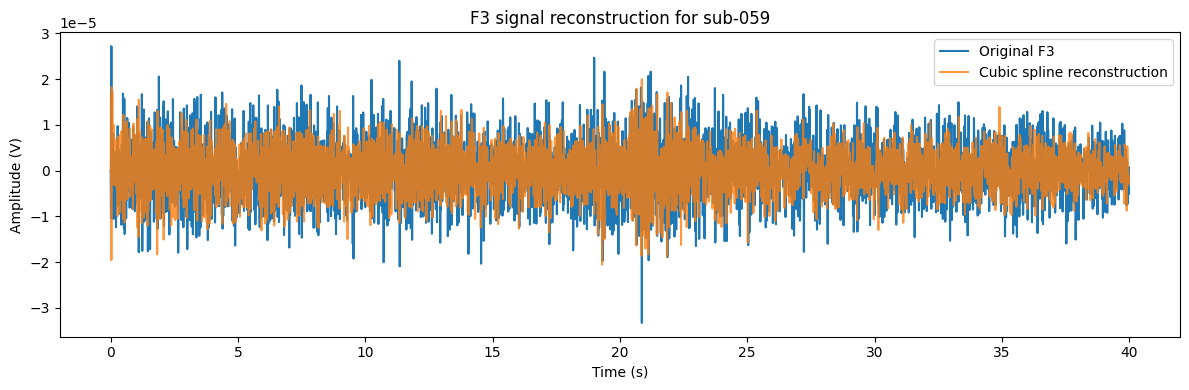

In [12]:
subject_to_plot = "sub-059"
preview_path = processed_dir / f"{subject_to_plot}_task-eyesclosed_eeg_cleaned_raw.fif"

if preview_path.exists():
    raw = mne.io.read_raw_fif(preview_path, preload=True, verbose=False)
    data = raw.get_data()
    ch_names = raw.ch_names
    fs = raw.info["sfreq"]

    available_neighbors = [ch for ch in neighbors if ch in ch_names]
    f3_original = data[ch_names.index(target_channel)]

    # Reuse the same spatial interpolation as in the metrics calculation.
    f3_cubic = cubic_spline_spatial_interpolation(
        data=data,
        ch_names=ch_names,
        coords=coords,
        target_channel=target_channel,
        available_neighbors=available_neighbors,
    )

    # Display a 20-second segment of the signals.
    start_sec = 0
    end_sec = 40
    start = int(start_sec * fs)
    end = int(end_sec * fs)
    time = np.arange(start, end) / fs

    plt.figure(figsize=(12, 4))
    plt.plot(time, f3_original[start:end], label="Original F3")
    plt.plot(time, f3_cubic[start:end], label="Cubic spline reconstruction", alpha=0.8)
    plt.title(f"F3 signal reconstruction for {subject_to_plot}")
    plt.xlabel("Time (s)")
    plt.ylabel("Amplitude (V)")
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print(f"Preview file not found: {preview_path}")